# 03 - Entrenamiento y evaluación de YOLO - AI Cook

**Objetivo:** entrenar un detector de ingredientes a partir de `ai_cook_clean` y evaluar su desempeño sobre un conjunto de test independiente.

- Dataset: **360 train / 103 valid / 51 test**, **30 clases**.
- Modelo inicial: **YOLO11n** con pesos preentrenados.
- Entrenamiento: máximo 50 épocas, imágenes de 640 px, batch 16.
- Los parámetros de augmentación se mantienen en sus valores por defecto (sin experimentos adicionales).
- El conjunto de test no se utiliza para entrenar ni elegir el modelo

> En Colab: ejecución --> GPU


## 1. Instalación y configuración del entorno

In [52]:
%pip -q install ultralytics pyyaml pandas matplotlib

In [53]:
import os
import json
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from ultralytics import YOLO
import ultralytics

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("GPU disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError("Activá GPU en Colab antes de entrenar.")

PyTorch: 2.14.1+cu130
Ultralytics: 8.4.218
GPU disponible: True
GPU: Tesla T4


## 2. Acceso a Drive y ubicación del dataset


In [54]:
from google.colab import drive
drive.mount("/content/drive")

# MODIFICAR ESTA RUTA si la carpeta está en otro lugar de Drive.
DATASET_SOURCE = Path("/content/drive/MyDrive/vision_pf/ai_cook_clean")

# Ejemplo alternativo si está dentro del repositorio:
# DATASET_SOURCE = Path("/content/drive/MyDrive/vision/artificial/datasets/ai_cook_clean")

assert DATASET_SOURCE.is_dir(), f"No se encontró el dataset en {DATASET_SOURCE}"
print("Dataset encontrado:", DATASET_SOURCE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset encontrado: /content/drive/MyDrive/vision_pf/ai_cook_clean


### Copiar dataset al disco de Colab

Copiarlo a `/content` para hacer elentrenamiento más rápido que leer todas las imágenes desde Drive. Los resultados finales se copiarán a Drive.

In [55]:
DATASET_DIR = Path("/content/vision_pf/ai_cook_clean")
if DATASET_DIR.exists():
    shutil.rmtree(DATASET_DIR)
shutil.copytree(DATASET_SOURCE, DATASET_DIR)

VALID_FOLDER = "valid" if (DATASET_DIR / "valid").exists() else "val"
for split in ["train", VALID_FOLDER, "test"]:
    for subdir in ["images", "labels"]:
        p = DATASET_DIR / split / subdir
        assert p.is_dir(), f"Falta la carpeta {p}"

for split in ["train", VALID_FOLDER, "test"]:
    images = [p for p in (DATASET_DIR / split / "images").iterdir()
              if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}]
    print(f"{split}: {len(images)} imágenes")

print("Carpetas verificadas")

train: 360 imágenes
valid: 103 imágenes
test: 51 imágenes
Carpetas verificadas.


## 3. Preparación del `data.yaml`


In [56]:
yaml_candidates = [DATASET_DIR / "data.yaml", DATASET_DIR / "dataset.yaml"]
original_yaml = next((p for p in yaml_candidates if p.is_file()), None)
assert original_yaml is not None, "No aparece data.yaml ni dataset.yaml en ai_cook_clean"

with original_yaml.open("r", encoding="utf-8") as f:
    original_config = yaml.safe_load(f)

names = original_config["names"]
if isinstance(names, dict):
    names = [names[k] for k in sorted(names, key=lambda x: int(x))]

assert len(names) == 30, f"Se esperaban 30 clases, pero el YAML tiene {len(names)}"

config = { "path": str(DATASET_DIR), "train": "train/images", "val": f"{VALID_FOLDER}/images", "test": "test/images", "nc": len(names), "names": names,}

DATA_YAML = Path("/content/vision_pf/ai_cook_yolo.yaml")
with DATA_YAML.open("w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False, allow_unicode=True)

print(DATA_YAML.read_text(encoding="utf-8"))

path: /content/vision_pf/ai_cook_clean
train: train/images
val: valid/images
test: test/images
nc: 30
names:
- apple
- banana
- beef
- blueberries
- bread
- butter
- carrot
- cheese
- chicken
- chicken_breast
- chocolate
- corn
- eggs
- flour
- goat_cheese
- green_beans
- ground_beef
- ham
- heavy_cream
- lime
- milk
- mushrooms
- onion
- potato
- shrimp
- spinach
- strawberries
- sugar
- sweet_potato
- tomato



## 4. Parámetros y entrenamiento

In [57]:
MODEL_NAME = "yolo11n.pt"  # baseline preentrenado
EPOCHS = 50
IMAGE_SIZE = 640
BATCH_SIZE = 16
PATIENCE = 15
DEVICE = 0

RUN_PROJECT = Path("/content/vision_pf/yolo_results")
RUN_NAME = "yolo11n_ai_cook_clean"

model = YOLO(MODEL_NAME)
train_results = model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMAGE_SIZE,  batch=BATCH_SIZE,   patience=PATIENCE,   device=DEVICE,   seed=SEED,   deterministic=True,   pretrained=True,   project=str(RUN_PROJECT),  name=RUN_NAME, exist_ok=True,plots=True,  save=True, verbose=True,)

RUN_DIR = Path(model.trainer.save_dir)
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
assert BEST_WEIGHTS.exists(), f"No se encontró {BEST_WEIGHTS}"
print("Mejores pesos:", BEST_WEIGHTS)




Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/vision_pf/ai_cook_yolo.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_ai_cook_clean, nbs=64, nms=None, opset=None,

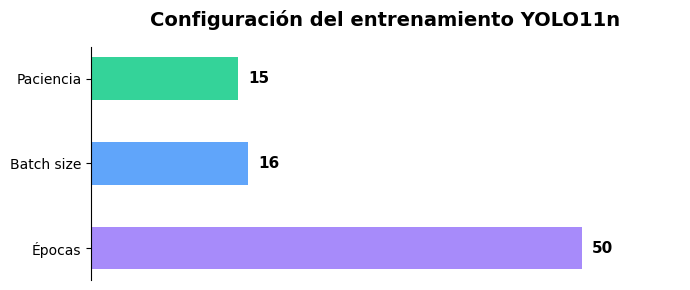

In [58]:
import matplotlib.pyplot as plt

params = {"Épocas": EPOCHS,"Batch size": BATCH_SIZE,  "Paciencia": PATIENCE}
fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(list(params.keys()),list(params.values()), color=["#A78BFA", "#60A5FA", "#34D399"],   height=0.5)

for bar in bars:
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width())}",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_xlim(0, max(params.values()) * 1.2)
ax.set_title("Configuración del entrenamiento YOLO11n", fontsize=14, fontweight="bold", pad=15)

ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.tick_params(axis="x", bottom=False, labelbottom=False)
ax.grid(False)

plt.tight_layout()
plt.show()

Se utilizó YOLO11n con pesos preentrenados, una resolución de 640 x 640 píxeles y un batch size de 16. Se estableció un máximo de 50 épocas y una paciencia de 15 para detener el entrenamiento cuando las métricas de validación dejaran de mejorar.

## 5. Curvas de entrenamiento

`results.csv` guarda las pérdidas y métricas por época. Los gráficos automáticos de Ultralytics también quedan en la carpeta del experimento.

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
25,26,290.835,0.89260,0.58085,0.98466,0.96088,0.96037,0.96703,0.64016,1.11422,0.55993,1.10396,0.000148,0.000148,0.000148
26,27,305.534,0.87465,0.55935,0.96474,0.95793,0.95441,0.96386,0.63651,1.13557,0.56118,1.11170,0.000143,0.000143,0.000143
27,28,316.657,0.86886,0.56743,0.96287,0.95748,0.94653,0.96538,0.64007,1.13612,0.56594,1.11845,0.000137,0.000137,0.000137
28,29,326.216,0.87971,0.57329,0.97038,0.94673,0.95717,0.96160,0.63990,1.12245,0.55655,1.10692,0.000131,0.000131,0.000131
29,30,337.288,0.85902,0.55145,0.96782,0.95012,0.96509,0.96823,0.63978,1.11931,0.55777,1.10435,0.000125,0.000125,0.000125


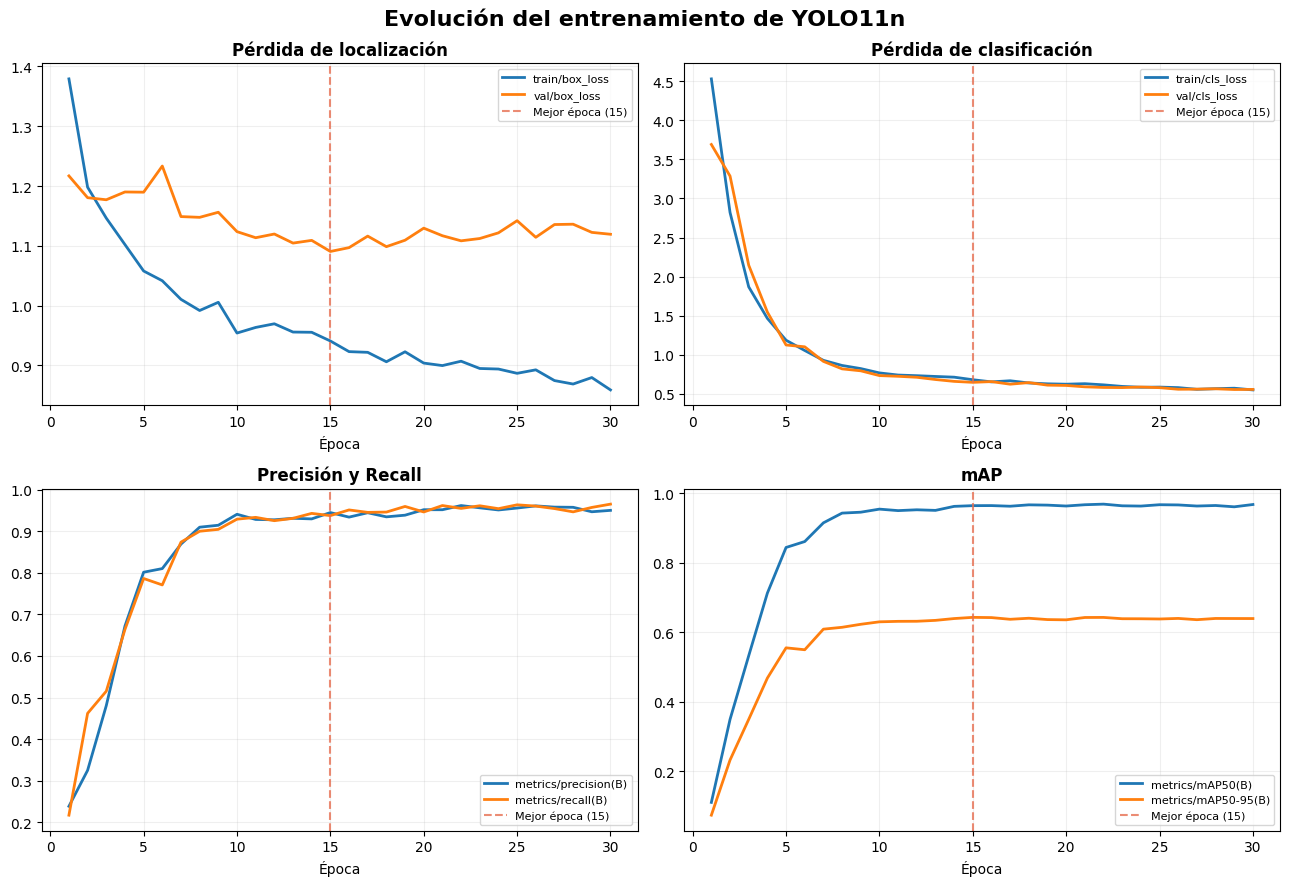

Mejor época: 15


In [59]:
csv_path = RUN_DIR / "results.csv"
assert csv_path.exists(), f"No se encontró {csv_path}"

history = pd.read_csv(csv_path)
history.columns = history.columns.str.strip()

display(history.tail())

# Identificar la mejor época a partir de los resultados guardados
best_epoch = int(history.loc[ history["metrics/mAP50-95(B)"].idxmax(), "epoch"])

metric_groups = [ ["train/box_loss", "val/box_loss"], ["train/cls_loss", "val/cls_loss"], ["metrics/precision(B)", "metrics/recall(B)"], ["metrics/mAP50(B)", "metrics/mAP50-95(B)"],]

titles = [ "Pérdida de localización", "Pérdida de clasificación", "Precisión y Recall", "mAP"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, columns, title in zip(axes.ravel(), metric_groups, titles):
    for col in columns:
        if col in history.columns:
            ax.plot(  history["epoch"],  history[col],  label=col,  linewidth=2)

    # Línea vertical que marca la mejor época
    ax.axvline( best_epoch, color="#E76F51",  linestyle="--",  linewidth=1.5,  alpha=0.8,  label=f"Mejor época ({best_epoch})")
    ax.set_xlabel("Época")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

fig.suptitle(
    "Evolución del entrenamiento de YOLO11n",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# Guardar gráfico
plt.savefig( RUN_DIR / "training_curves_custom.png",  dpi=300,  bbox_inches="tight")

plt.show()

print(f"Mejor época: {best_epoch}")

Durante las primeras épocas se observa una rápida mejora del modelo, con una disminución de las pérdidas y un aumento de la precisión, el recall y el mAP. Posteriormente, las métricas se estabilizan. El entrenamiento finalizó en la época 30 mediante *early stopping*, conservando los mejores pesos de la época 15. Esto indica que continuar entrenando no produjo mejoras sostenidas en la validación.

## 6. Evaluación final en test

Se carga `best.pt` y se evalúa una sola vez sobre las 51 imágenes de test. Las métricas se calculan con las anotaciones originales.

In [60]:
best_model = YOLO(str(BEST_WEIGHTS))

test_metrics = best_model.val(data=str(DATA_YAML), split="test", imgsz=IMAGE_SIZE, batch=BATCH_SIZE, device=DEVICE, plots=True, project=str(RUN_PROJECT), name="test_evaluation", exist_ok=True,)

summary = {
    "precision": float(test_metrics.box.mp),
    "recall": float(test_metrics.box.mr),
    "mAP50": float(test_metrics.box.map50),
    "mAP50_95": float(test_metrics.box.map),
    "n_train": 360,
    "n_val": 103,
    "n_test": 51,
    "num_classes": len(names),
    "model": MODEL_NAME,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
}

print(pd.DataFrame([summary]).T.to_string(header=False))

with (RUN_DIR / "test_metrics.json").open("w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,604,098 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1970.9±624.4 MB/s, size: 174.4 KB)
val: Scanning /content/vision_pf/ai_cook_clean/test/labels... 51 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 51/51 1.2Kit/s 0.0s
val: New cache created: /content/vision_pf/ai_cook_clean/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.0s/it 4.0s
                   all         51        610      0.896       0.93      0.946       0.67
                 apple         26         26      0.892      0.951      0.935      0.708
                banana          6          6      0.908          1      0.995        0.8
                  beef         31         31      0.849      0.543       0.86      0.336
           blueberries         21         21      0.989

En el conjunto de test, compuesto por 51 imágenes, YOLO11n obtuvo un mAP@50 de 94,6 %, una precisión de 89,6 % y un recall de 93%. Estos resultados indican una buena capacidad general de detección. Sin embargo, el mAP@50-95 de 67% muestra que la localización de los objetos todavía puede mejorar cuando se utilizan criterios más estrictos de superposición.

## 7. Resultados por ingrediente

,Ingrediente,Cantidad en test
0,apple,26
1,banana,6
2,beef,31
3,blueberries,21
4,bread,28
5,butter,12
6,carrot,16
7,cheese,30
8,chicken,33
9,chicken_breast,25


Clases sin ejemplos en test:


,Ingrediente,Cantidad en test
14,goat_cheese,0
17,ham,0


,class_id,ingredient,n_test,mAP50_95
5,5,butter,12,0.859699
21,21,mushrooms,13,0.825804
28,28,sweet_potato,12,0.801150
1,1,banana,6,0.800125
18,18,heavy_cream,6,0.794833
27,27,sugar,12,0.778909
22,22,onion,21,0.778602
12,12,eggs,47,0.731212
13,13,flour,46,0.729565
26,26,strawberries,24,0.726773


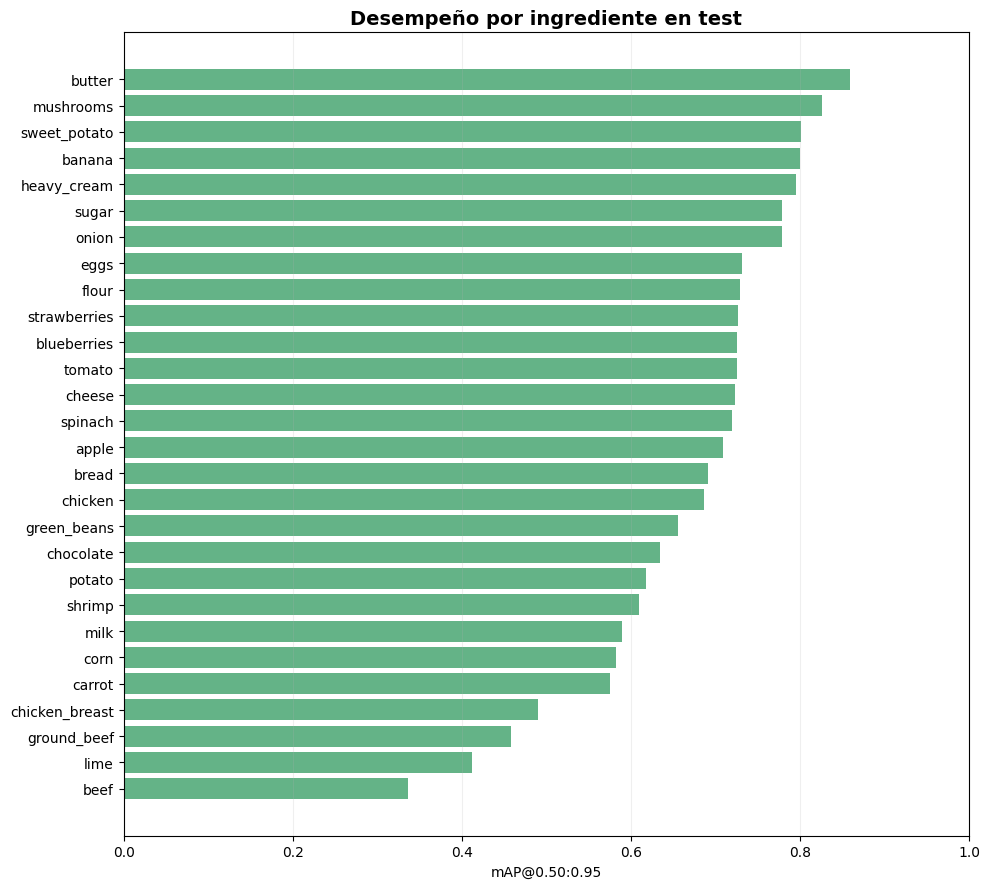

In [66]:
#antes de verificar el desempeno por clase, nos fijamos si el test tiene todos los ejemplos de clase (30) porque sino la metrica para algun ingrediente puede no cambiar yv no nos dice nada
from collections import Counter

counts = Counter()

# Contar ingredientes reales en test
for label_file in (DATASET_DIR / "test" / "labels").glob("*.txt"):
    for line in label_file.read_text().splitlines():
        if line.strip():
            class_id = int(line.split()[0])
            counts[class_id] += 1

# Crear tabla
class_counts = pd.DataFrame({
    "Ingrediente": names,
    "Cantidad en test": [counts[i] for i in range(len(names))]
})

display(class_counts)

# Mostrar clases sin ejemplos
missing = class_counts[
    class_counts["Cantidad en test"] == 0
]

if missing.empty:
    print("Todas las clases tienen ejemplos en test.")
else:
    print("Clases sin ejemplos en test:")
    display(missing)



# mAP@50-95 por ingrediente
class_ap = test_metrics.box.maps

per_class = pd.DataFrame({
    "class_id": list(range(len(names))),
    "ingredient": names,
    "n_test": [counts[i] for i in range(len(names))],
    "mAP50_95": class_ap,
})

# Excluir clases sin ejemplos reales en test
per_class = per_class[per_class["n_test"] > 0].copy()

# Ordenar de mayor a menor rendimiento
per_class = per_class.sort_values("mAP50_95", ascending=False)

display(per_class)

# Guardar resultados
per_class.to_csv( RUN_DIR / "test_per_class.csv", index=False)

plt.figure(figsize=(10, 9))
plt.barh( per_class["ingredient"], per_class["mAP50_95"], color="#64b387")

plt.gca().invert_yaxis()
plt.xlabel("mAP@0.50:0.95")
plt.title( "Desempeño por ingrediente en test", fontsize=14, fontweight="bold")

plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

El rendimiento varía según el ingrediente. Las clases con mejores resultados incluyen *butter* (86%), *mushrooms* (82,6%) y *sweet_potato* (80,1%). En cambio, *beef* (33,6%), *lime* (41,2%) y *ground_beef* (45,8%) presentan mayores dificultades. Esto evidencia que, aunque el rendimiento global es bueno, existen diferencias importantes entre las clases.


Las clases goat_cheese y ham no se incluyeron en el análisis por ingrediente, ya que no cuentan con ejemplos anotados en el conjunto de test.

## 8. Matriz de confusión y predicciones visuales

confusion_matrix.png


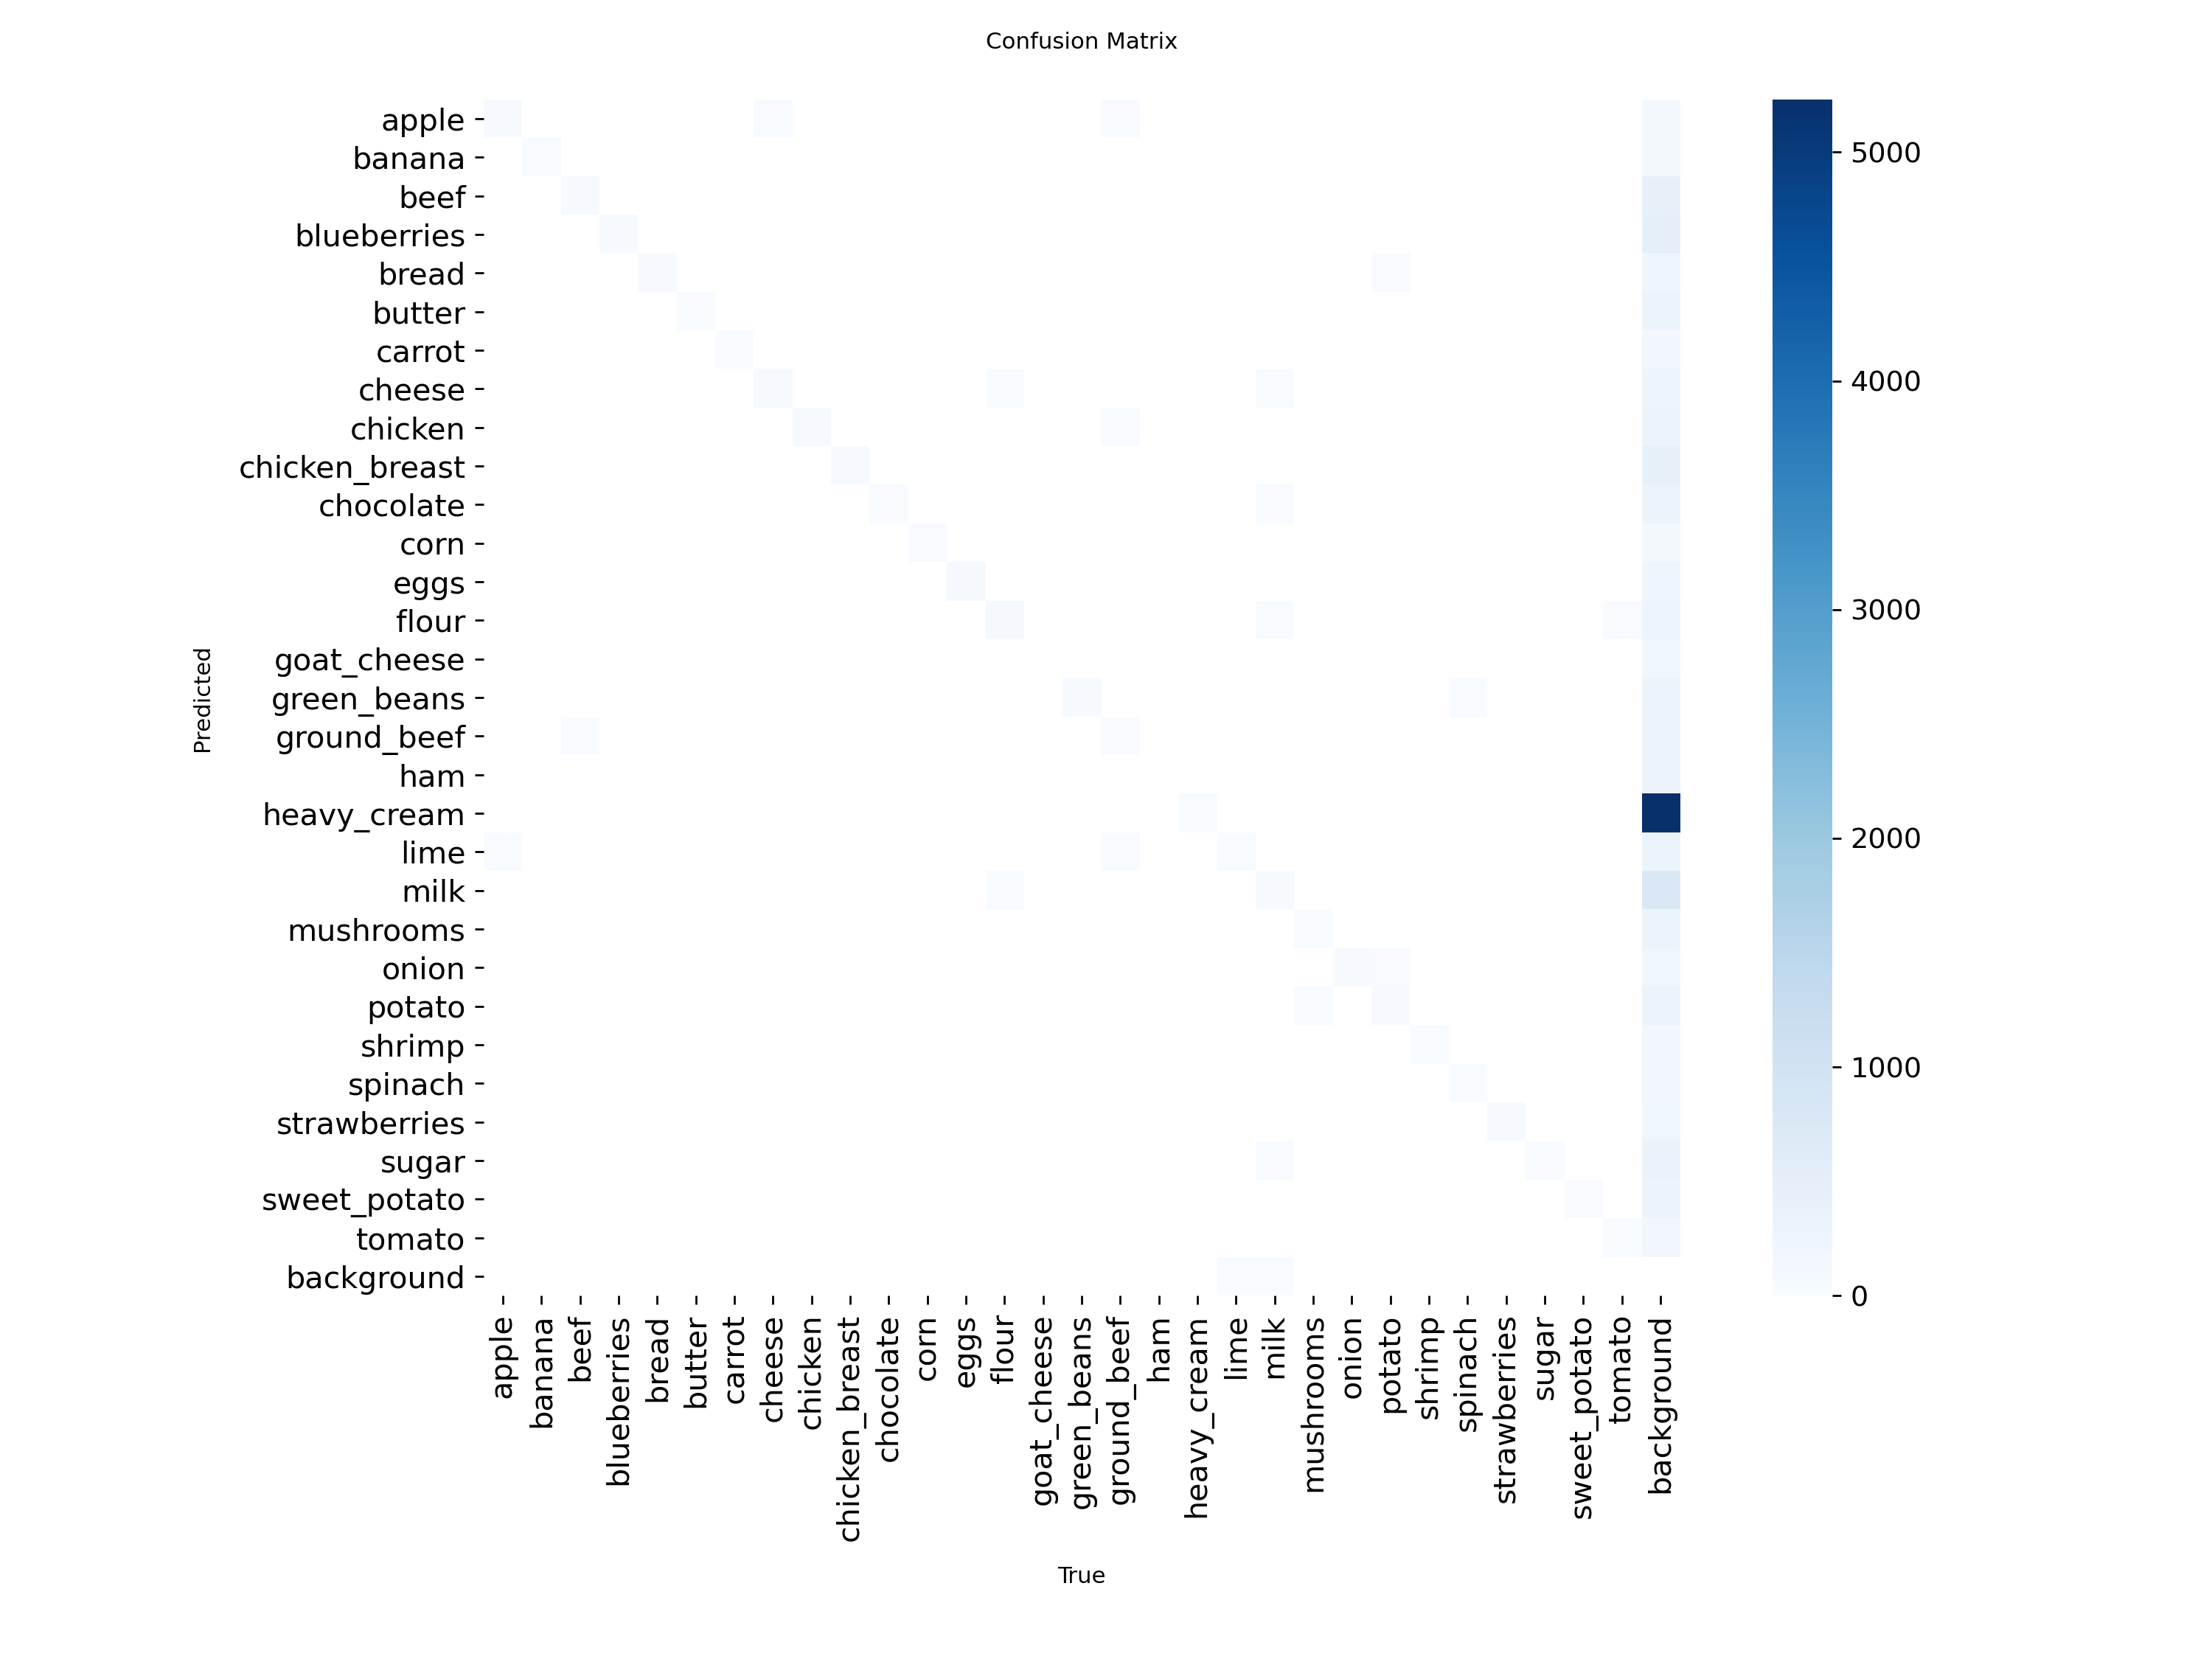

confusion_matrix_normalized.png


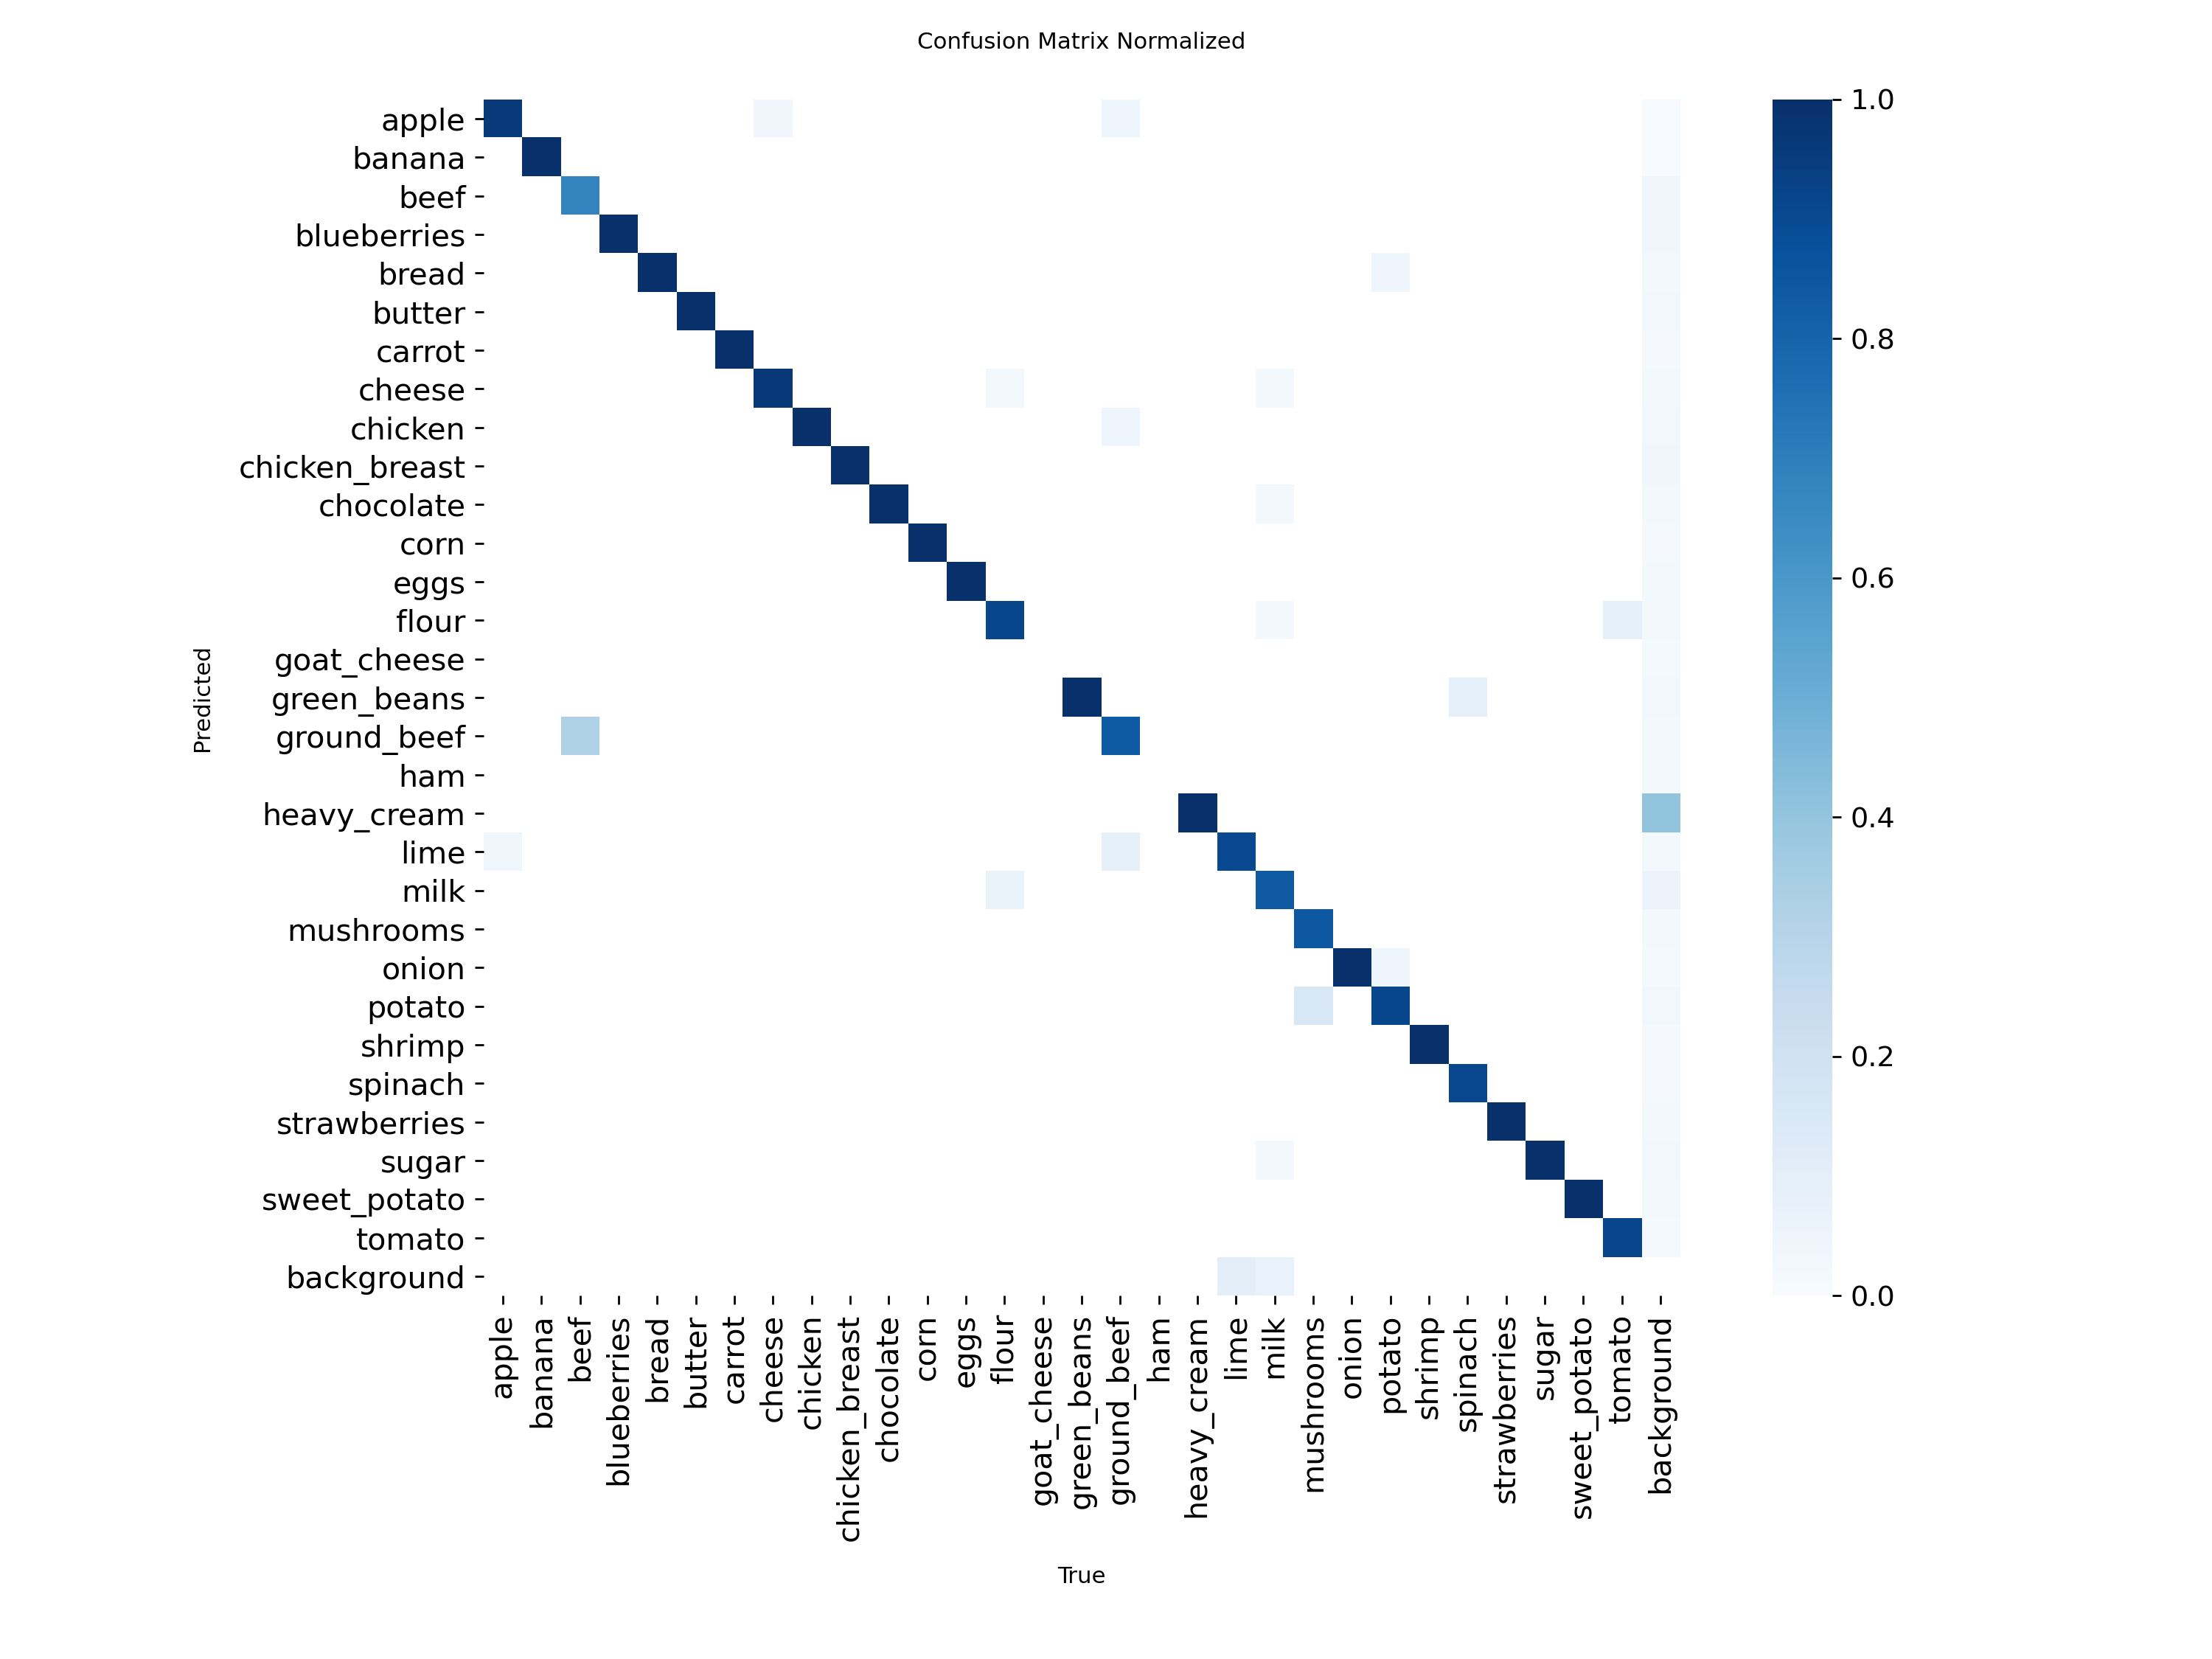

In [62]:
from IPython.display import display, Image as DisplayImage

eval_dir  = Path(test_metrics.save_dir)
for filename in ["confusion_matrix.png", "confusion_matrix_normalized.png", "PR_curve.png"]:
    image_path = eval_dir / filename
    if image_path.exists():
        print(filename)
        display(DisplayImage(filename=str(image_path), width=800))

La matriz no normalizada indicaría resultados muy malos porque una sola clase, heavy_cream, tiene muchísimos falsos positivos y domina la escala de colores, haciendo que las demás celdas parezcan blancas y dificultando así la visualizacion de sus resultados.

La matriz normalizada permite observar con mayor claridad una diagonal predominante, lo que indica una alta proporción de detecciones correctas para la mayoría de los ingredientes. Las confusiones entre clases son relativamente reducidas. No obstante, la normalización no elimina los falsos positivos observados en la matriz original.

Results saved to /content/vision_pf/yolo_results/test_predictions


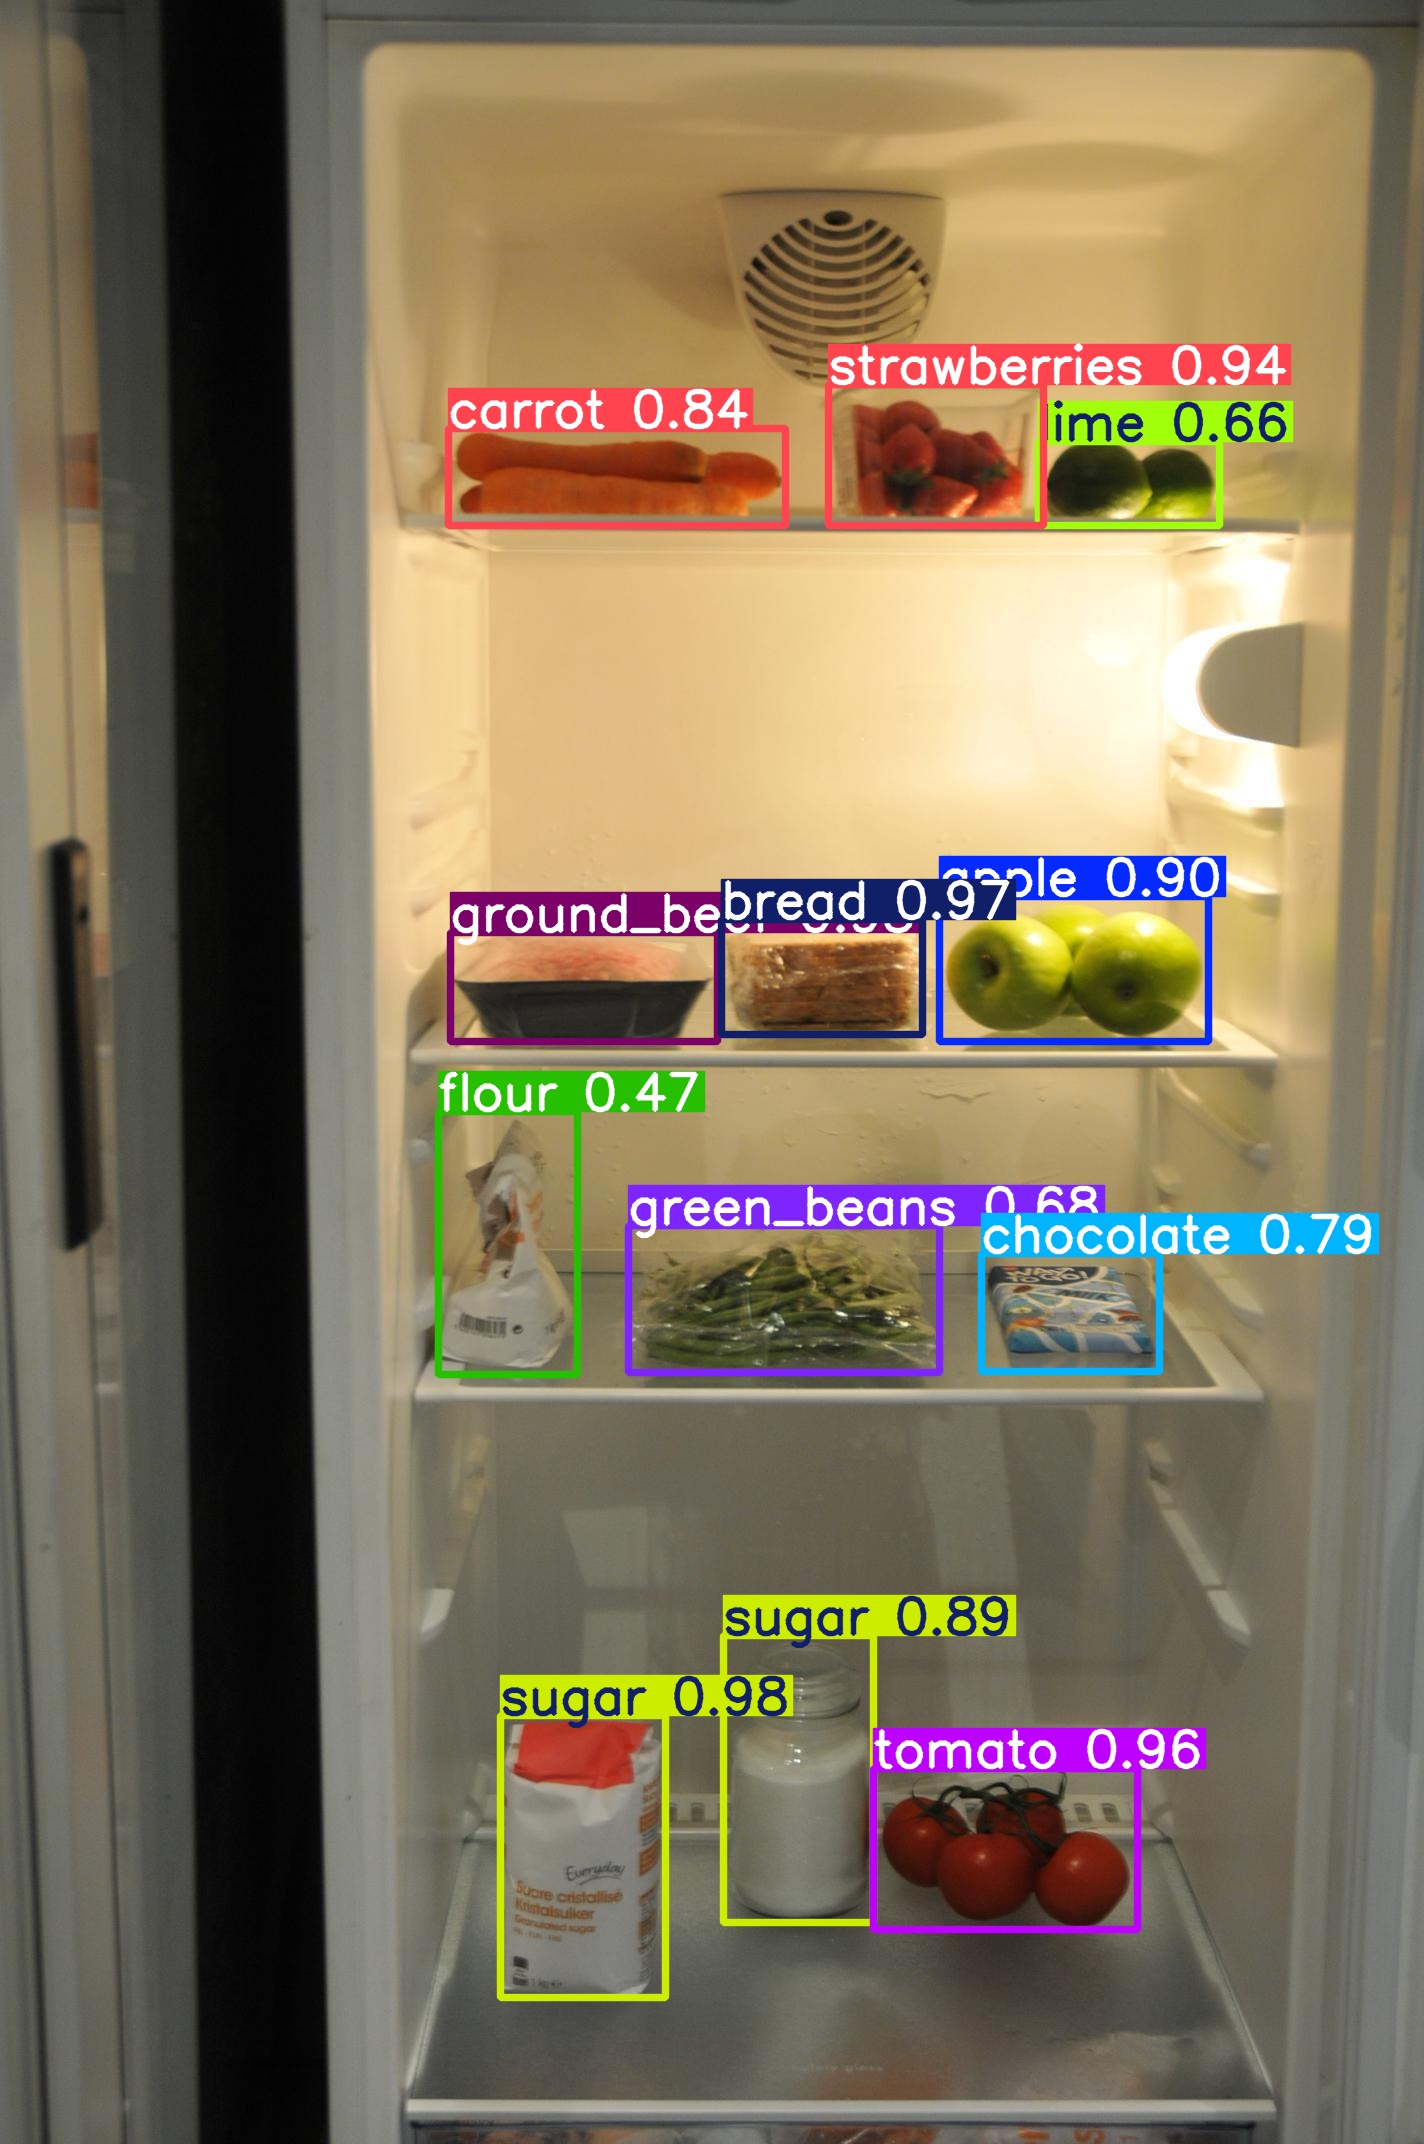

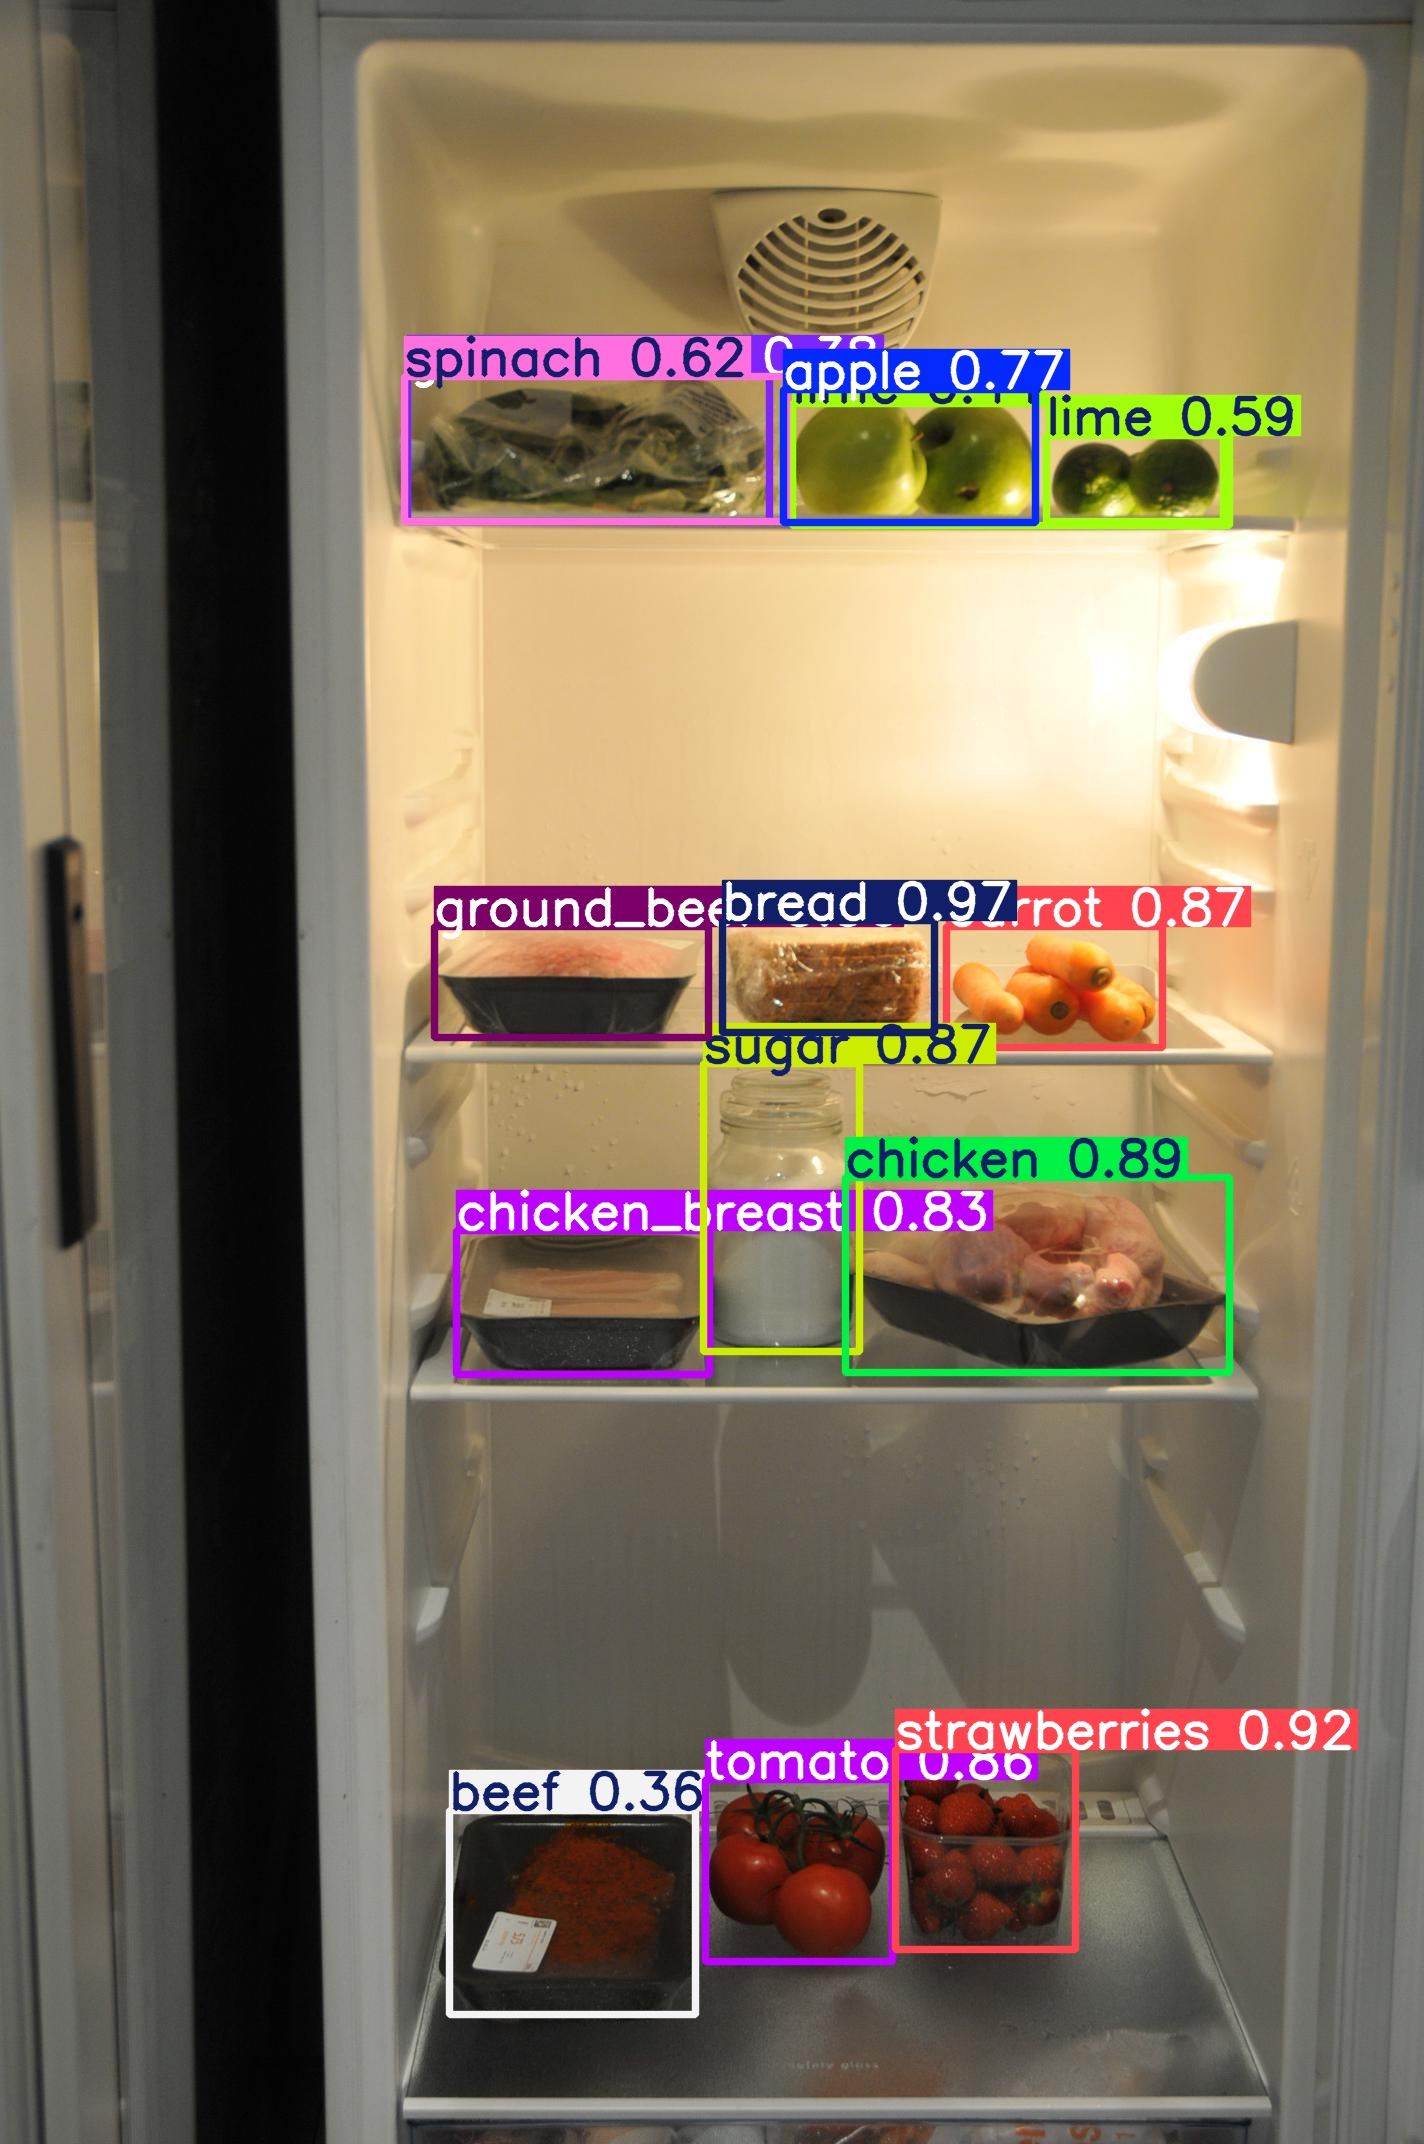

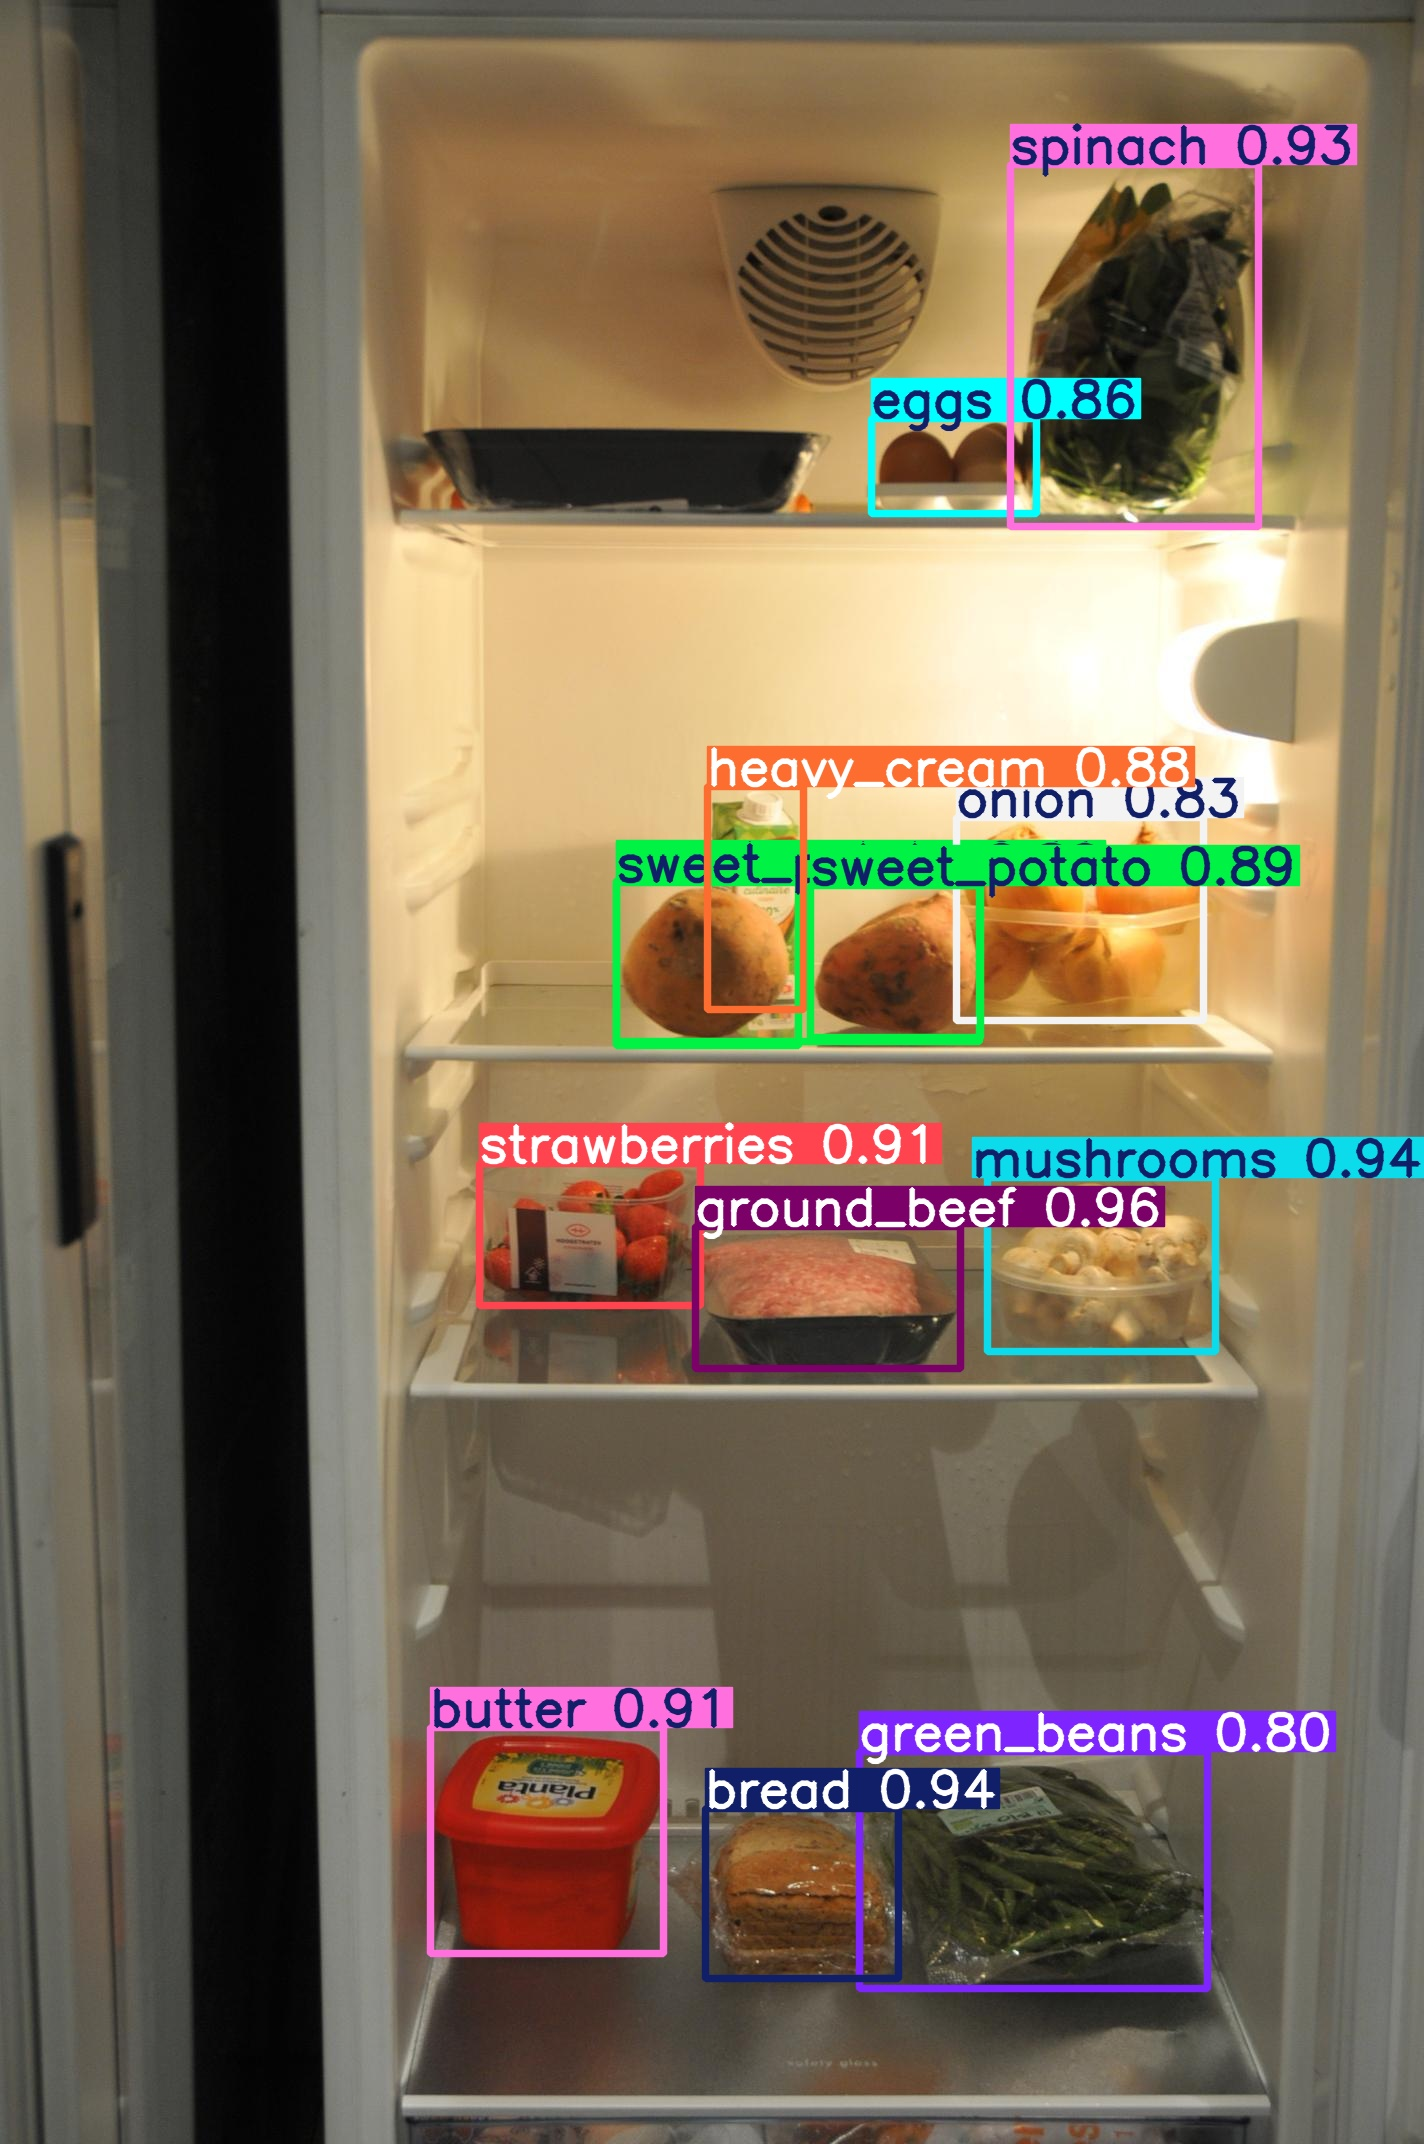

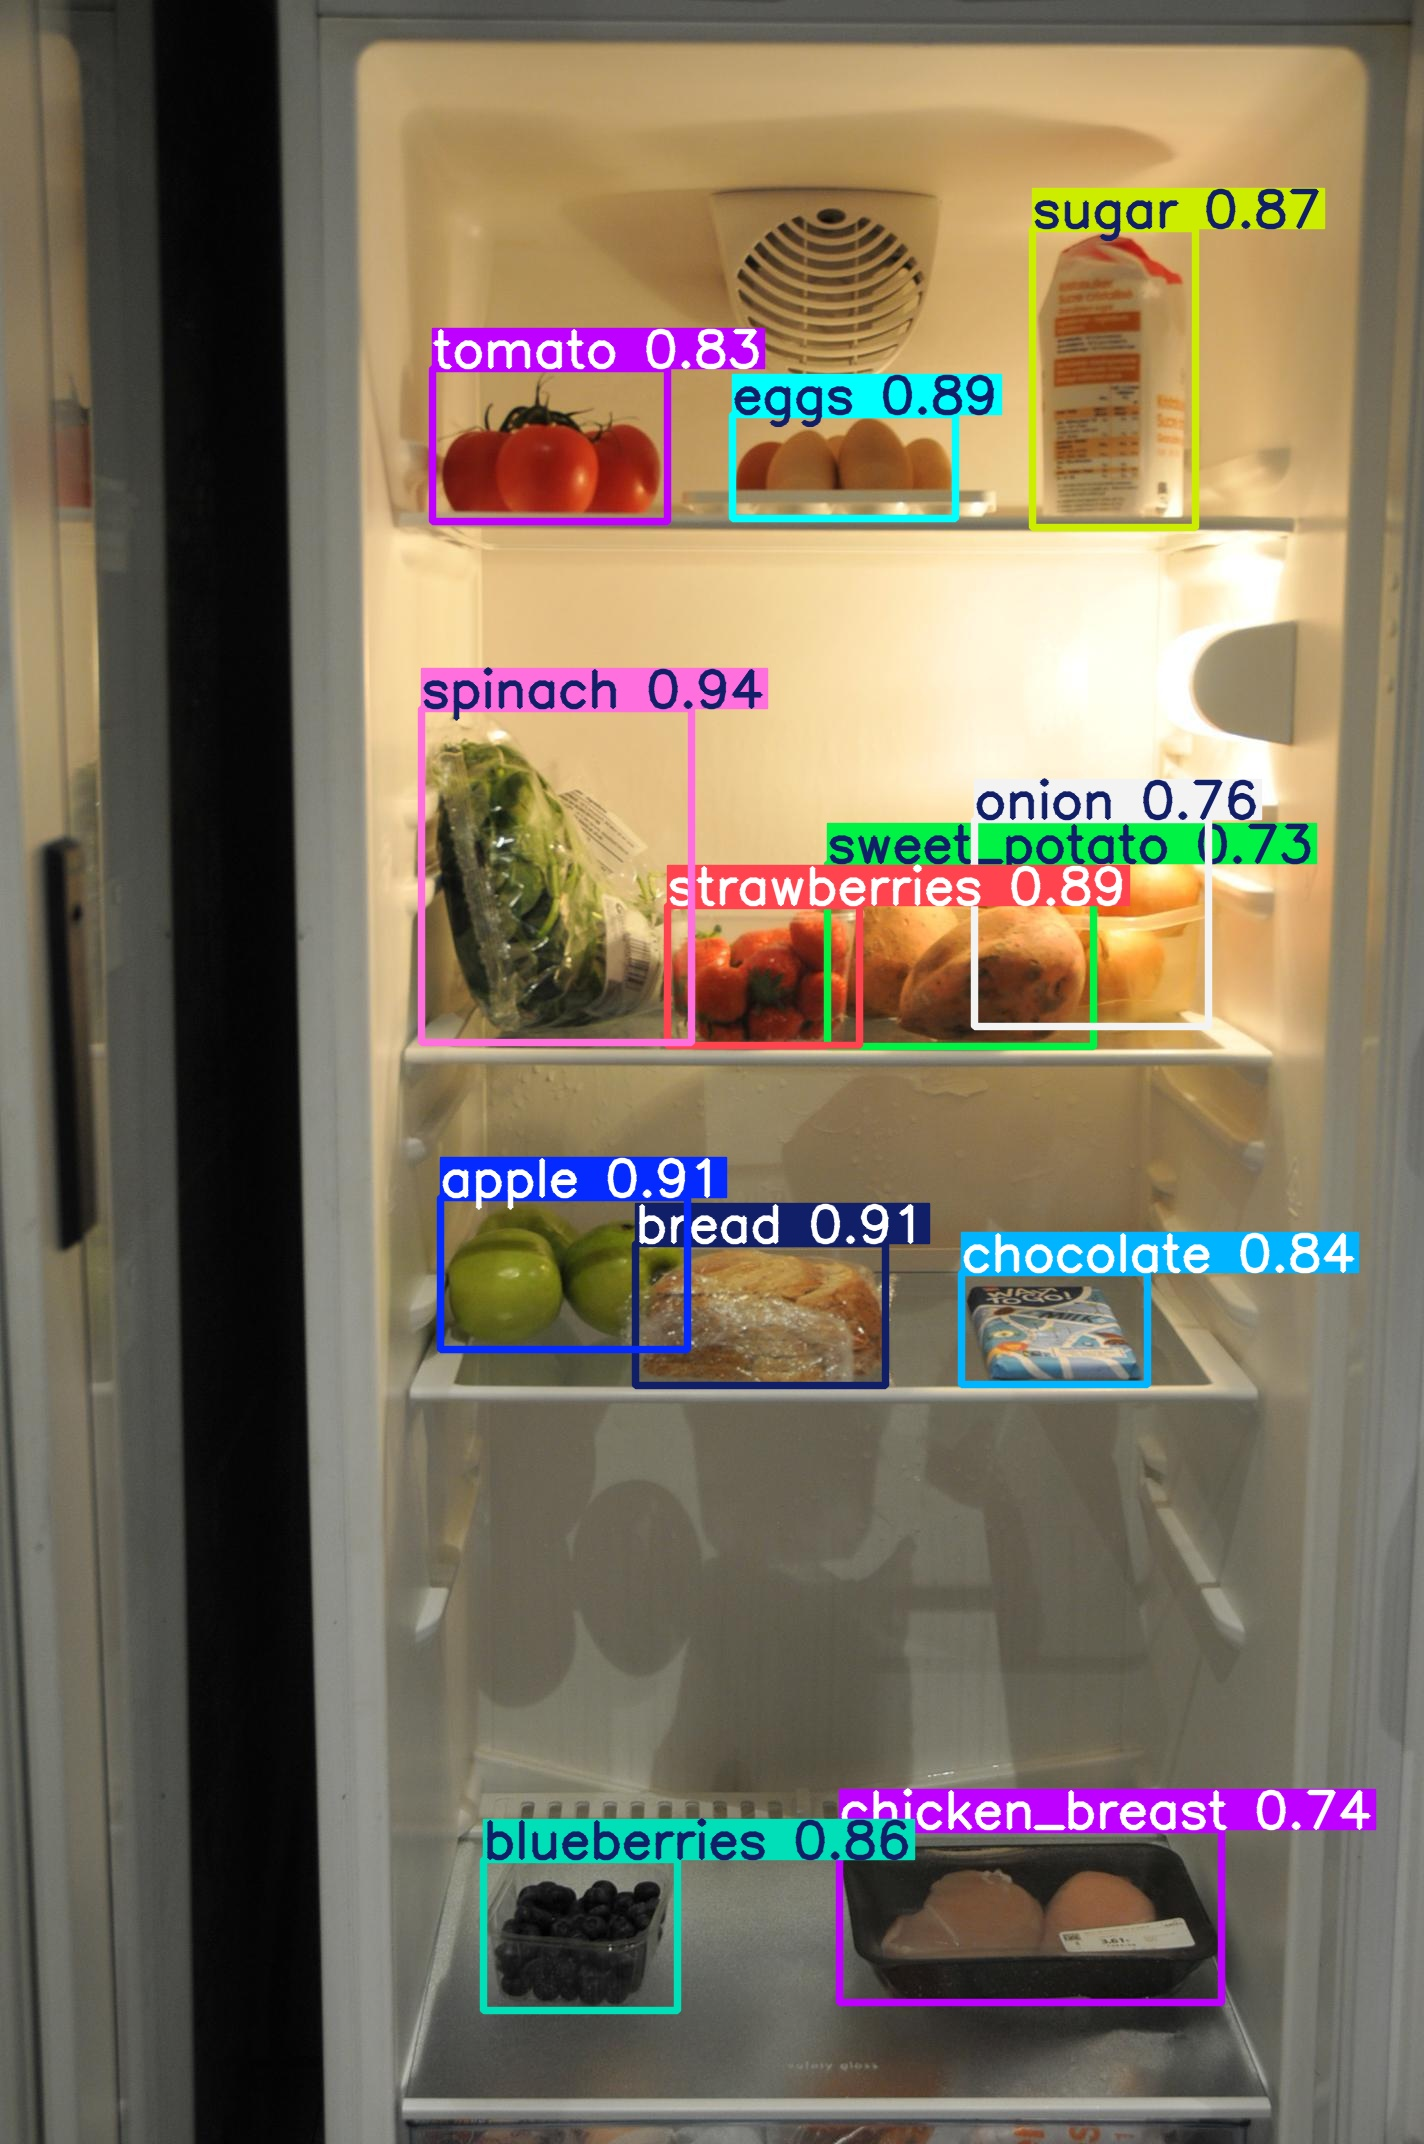

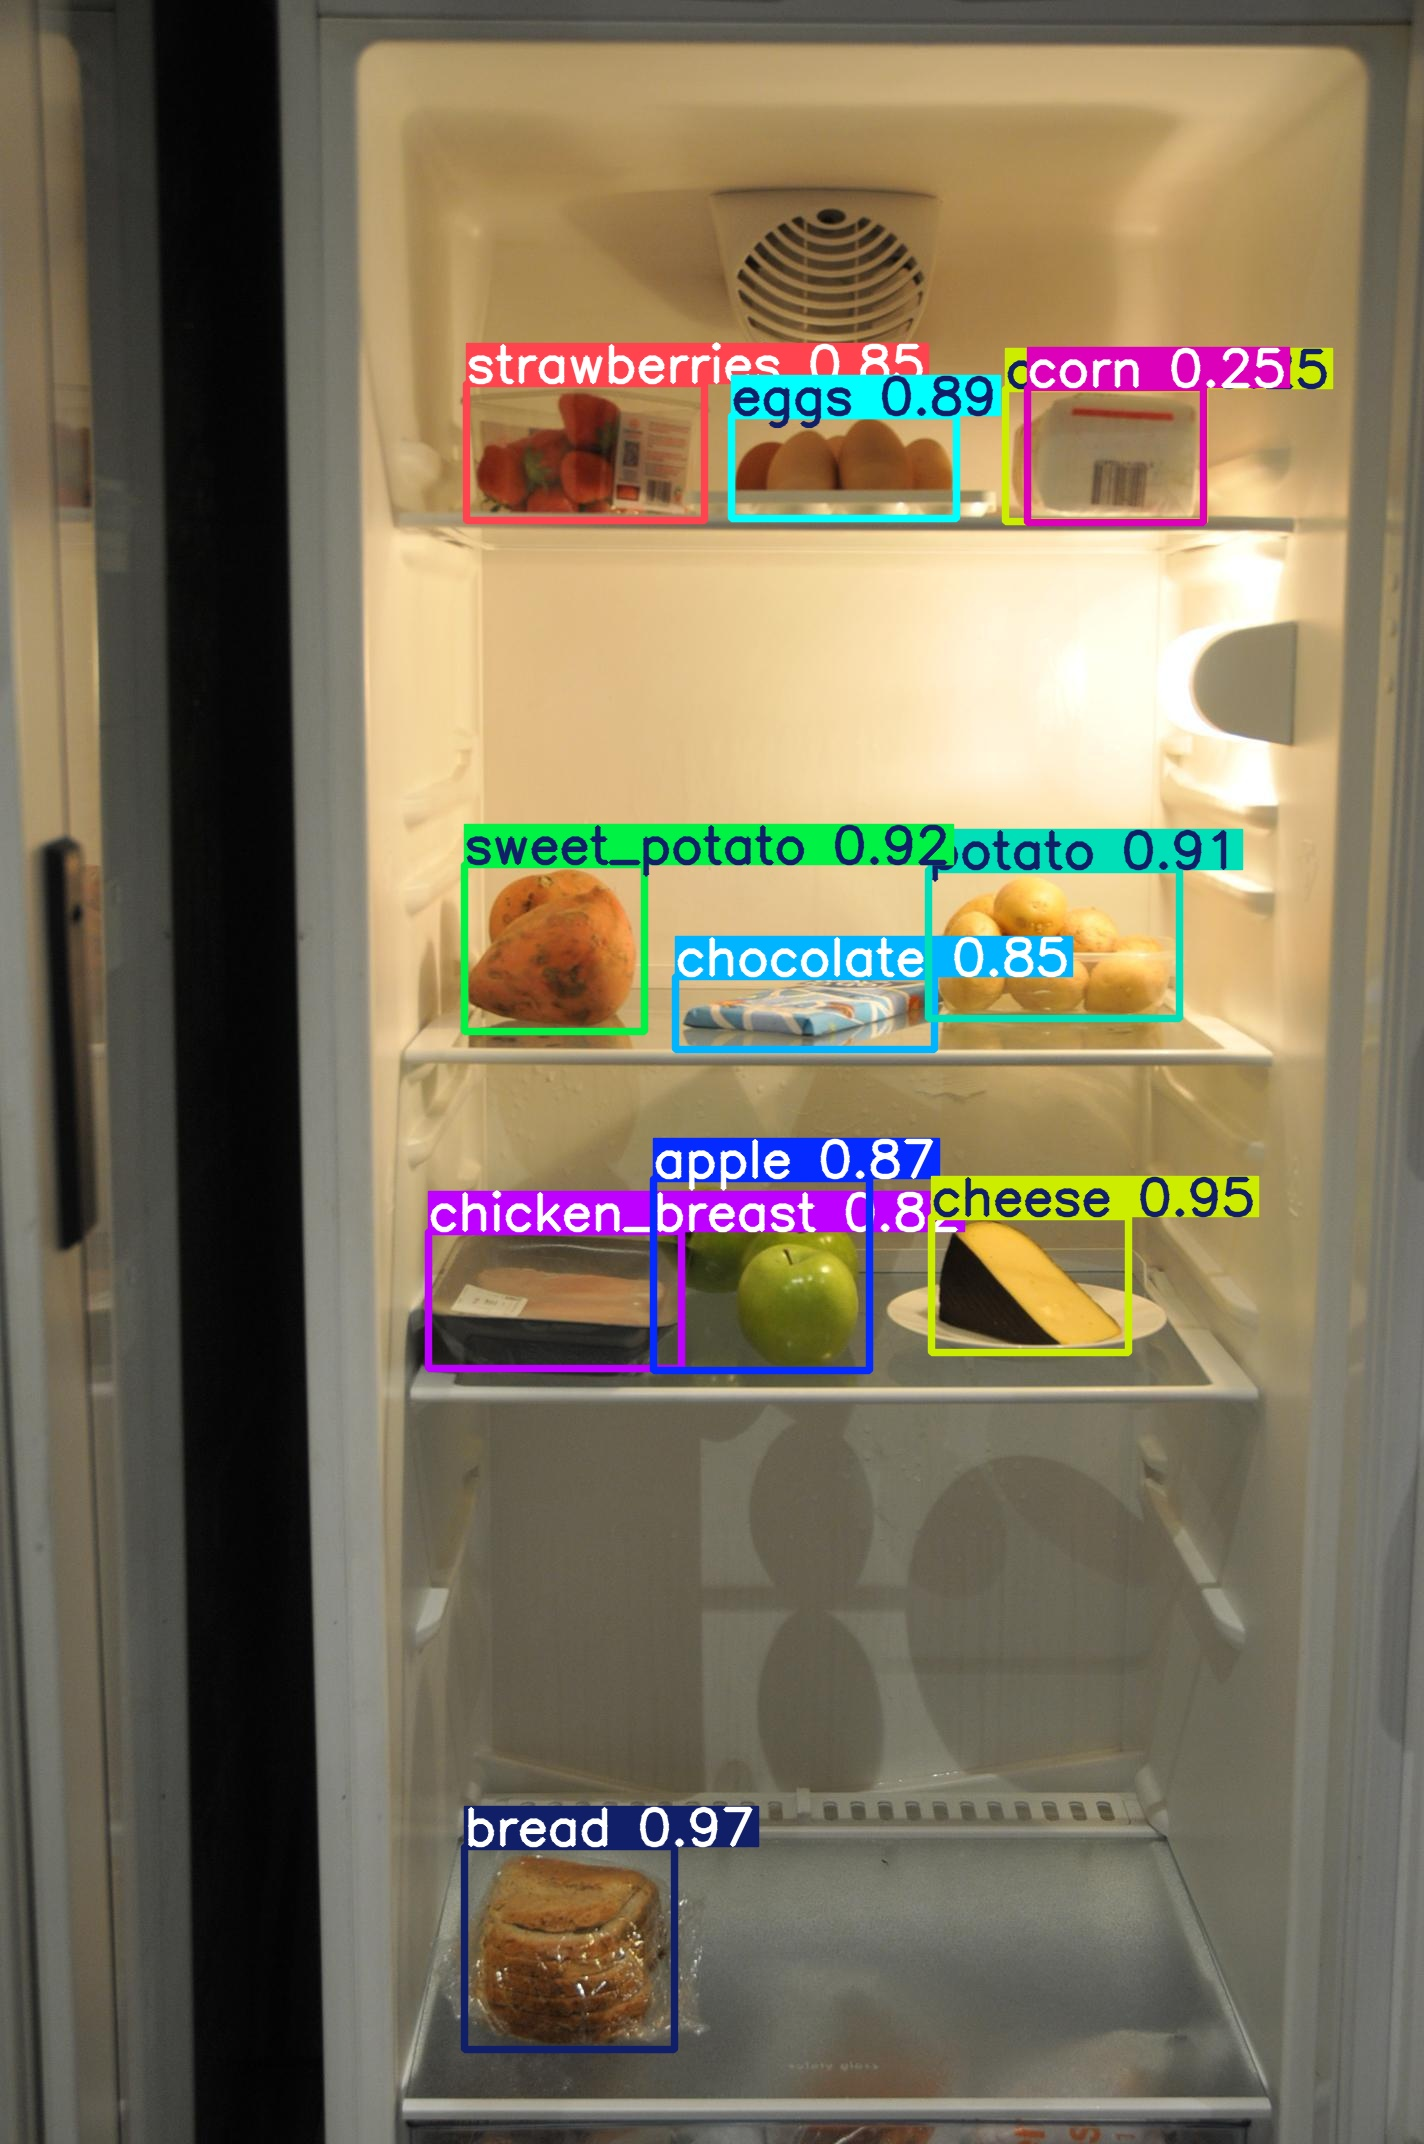

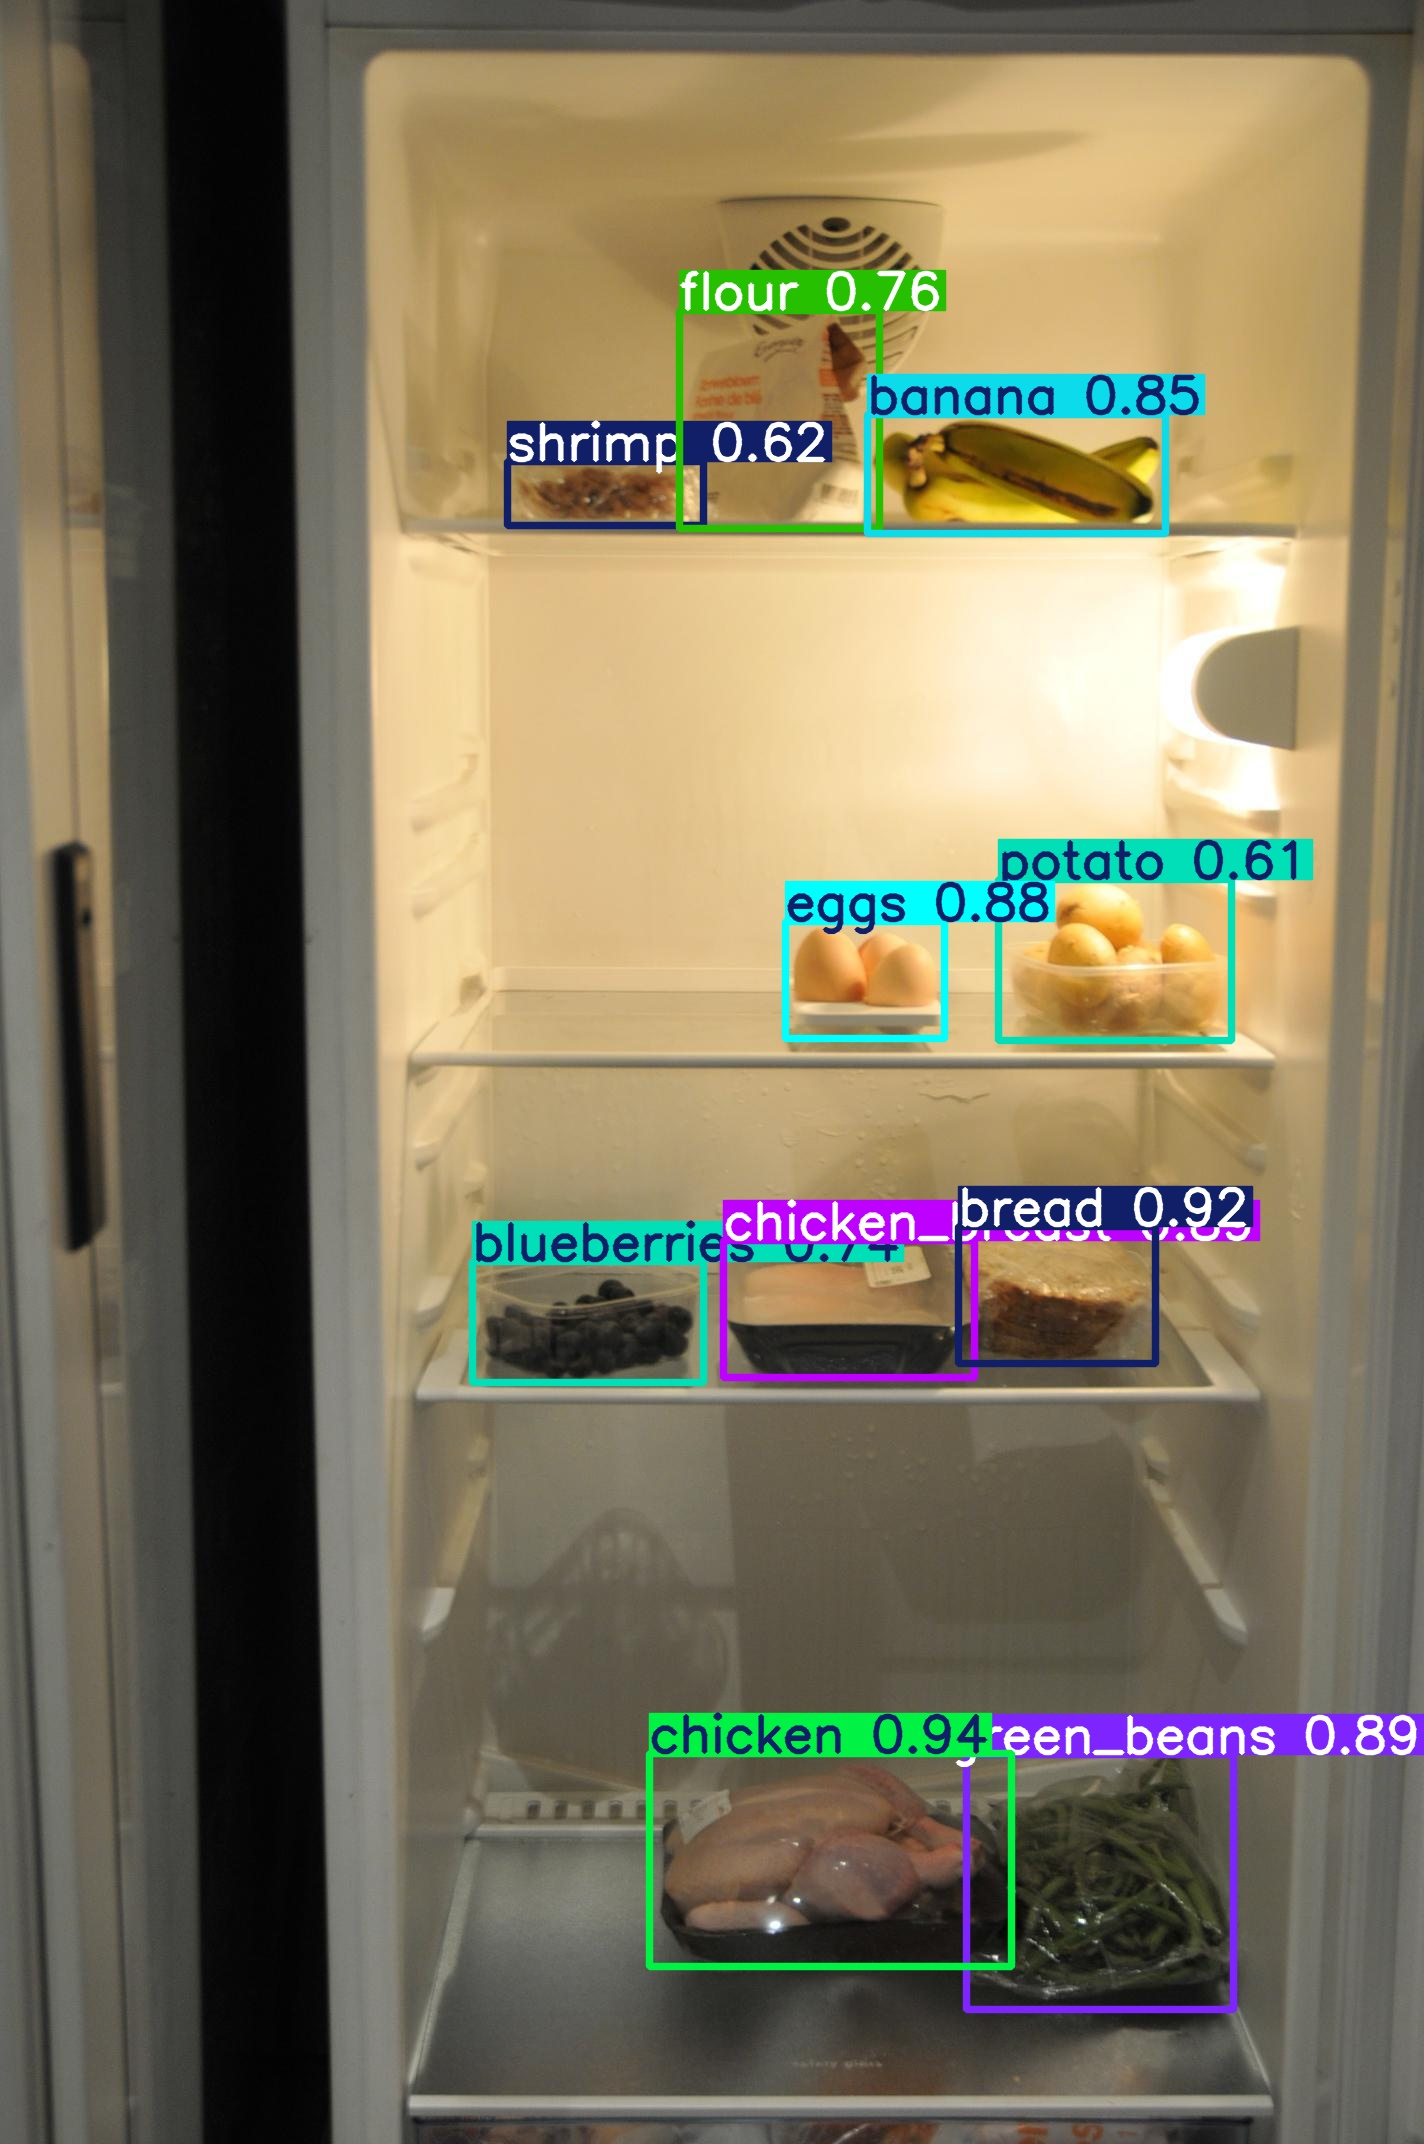

In [51]:
#probamos haacer predicciones de test con nuestro mejor modelo
#miramos las primemras 6

test_images_dir = DATASET_DIR / "test" / "images"

prediction_results = best_model.predict(
    source=str(test_images_dir),
    imgsz=IMAGE_SIZE,
    conf=0.25,
    device=DEVICE,
    save=True,
    project=str(RUN_PROJECT),
    name="test_predictions",
    exist_ok=True,
    verbose=False,
)

prediction_dir = Path(prediction_results[0].save_dir)
example_paths = sorted([
    p for p in prediction_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
])[:6]

for path in example_paths:
    display(DisplayImage(filename=str(path), width=550))

## 9. Guardar resultados y modelo en Drive

Se guardan pesos, métricas, gráficos y predicciones para el informe.

In [63]:
DRIVE_OUTPUT = Path("/content/drive/MyDrive/vision_pf/vision_artificial_yolo")
DRIVE_OUTPUT.mkdir(parents=True, exist_ok=True)

# Copiamos las salidas de train, test y predict.
for folder in [RUN_DIR, RUN_PROJECT / "test_evaluation", RUN_PROJECT / "test_predictions"]:
    if folder.exists():
        target = DRIVE_OUTPUT / folder.name
        if target.exists():
            shutil.rmtree(target)
        shutil.copytree(folder, target)

shutil.copy2(DATA_YAML, DRIVE_OUTPUT / "ai_cook_yolo.yaml")

print("Resultados guardados en:", DRIVE_OUTPUT)
print("Modelo entrenado:", DRIVE_OUTPUT / RUN_NAME / "weights" / "best.pt")

Resultados guardados en: /content/drive/MyDrive/vision_pf/vision_artificial_yolo
Modelo entrenado: /content/drive/MyDrive/vision_pf/vision_artificial_yolo/yolo11n_ai_cook_clean/weights/best.pt


## 10. Registro para reproducibilidad

Para comparar con RT-DETR es importante documentar: versión de librerías, GPU, tamaño de imagen, particiones, semilla, batch, número de parámetros, latencia y métricas sobre **el mismo test**. El tiempo/FPS se debe medir después, bajo condiciones equivalentes y con un protocolo común para ambos modelos.


In [64]:
params = sum(p.numel() for p in best_model.model.parameters())
run_info = {
    **summary,
    "parameters": int(params),
    "epochs_completed": int(len(history)),
    "torch_version": torch.__version__,
    "ultralytics_version": ultralytics.__version__,
    "gpu": torch.cuda.get_device_name(0),
}

with (DRIVE_OUTPUT / "experiment_info.json").open("w", encoding="utf-8") as f:
    json.dump(run_info, f, ensure_ascii=False, indent=2)

print(json.dumps(run_info, ensure_ascii=False, indent=2))

{
  "precision": 0.8958607852353315,
  "recall": 0.929998628928409,
  "mAP50": 0.9455211256583685,
  "mAP50_95": 0.6703937022271733,
  "n_train": 360,
  "n_val": 103,
  "n_test": 51,
  "num_classes": 30,
  "model": "yolo11n.pt",
  "image_size": 640,
  "batch_size": 16,
  "seed": 42,
  "parameters": 2611930,
  "epochs_completed": 30,
  "torch_version": "2.14.1+cu130",
  "ultralytics_version": "8.4.218",
  "gpu": "Tesla T4"
}
